In [ ]:
from google.colab import files
uploaded = files.upload()

Saving description.txt to description (2).txt
Saving test_data.txt to test_data (2).txt
Saving test_data_solution.txt to test_data_solution (2).txt
Saving train_data.txt to train_data (2).txt


### Step 1: Data Loading & Preprocessing

In this step, we read and parse the custom formatted text datasets (`train_data.txt`, `test_data.txt`, and `test_data_solution.txt`). The raw records are structured with a special delimiter (` ::: `) separating unique fields including Movie ID, Title, Genre, and Plot Description. We parse these lines and structure them into highly organized pandas DataFrames for downstream analytical processing.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

def load_data(file_path, has_genre=True):
    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split(' ::: ')
            if len(parts) >= 3:
                movie_id = parts[0]
                title = parts[1]
                if has_genre:
                    genre = parts[2]
                    description = ' '.join(parts[3:])
                    data.append((movie_id, title, genre, description))
                else:
                    description = ' '.join(parts[2:])
                    data.append((movie_id, title, description))
    if has_genre:
        return pd.DataFrame(data, columns=['ID', 'TITLE', 'GENRE', 'DESCRIPTION'])
    else:
        return pd.DataFrame(data, columns=['ID', 'TITLE', 'DESCRIPTION'])

print("Loading train data...")
train_df = load_data('train_data.txt', has_genre=True)
print(f"Loaded {len(train_df)} training samples.")

print("Loading test data...")
test_df = load_data('test_data.txt', has_genre=False)
print(f"Loaded {len(test_df)} test samples.")

print("Loading test solutions...")
test_sol_df = load_data('test_data_solution.txt', has_genre=True)
print(f"Loaded {len(test_sol_df)} ground truth samples.")

display(train_df.head())

Loading train data...
Loaded 54214 training samples.
Loading test data...
Loaded 54200 test samples.
Loading test solutions...
Loaded 54200 ground truth samples.


,ID,TITLE,GENRE,DESCRIPTION
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


### Step 2: Feature Extraction using TF-IDF

We vectorize the text-based plot descriptions using Term Frequency-Inverse Document Frequency (TF-IDF). Stop words (e.g., highly common English helper words) are filtered out, and the vocabulary size is limited to the top 10,000 features. This transforms raw, unstructured natural language text into a highly structured, sparse numerical matrix ready for machine learning classifiers.

In [ ]:
print("Vectorizing text...")
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')

X_train = vectorizer.fit_transform(train_df['DESCRIPTION'])
y_train = train_df['GENRE']

X_test = vectorizer.transform(test_df['DESCRIPTION'])
y_test = test_sol_df['GENRE']

print(f"Train features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")

Vectorizing text...
Train features shape: (54214, 10000)
Test features shape: (54200, 10000)


### Step 3: Classifier Model Training & Prediction

We initialize and train a multinomial **Logistic Regression** classifier using the optimized SAGA optimization solver, which is highly efficient for large sparse matrices. Once fitted on the training features, the model generates classification predictions on the unseen test dataset plot descriptions.

In [ ]:
print("Training the classifier...")
clf = LogisticRegression(max_iter=1000, C=1.0, solver='saga', multi_class='multinomial')
clf.fit(X_train, y_train)

print("Evaluating the model...")
y_pred = clf.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nCONCLUSION: The model has been built successfully and evaluated using TF-IDF features with Logistic Regression. SUCCESSFUL!")

Training the classifier...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Evaluating the model...
Accuracy: 0.5886

Classification Report:
              precision    recall  f1-score   support

      action       0.51      0.29      0.37      1314
       adult       0.62      0.24      0.35       590
   adventure       0.64      0.16      0.26       775
   animation       0.52      0.05      0.09       498
   biography       0.00      0.00      0.00       264
      comedy       0.54      0.59      0.56      7446
       crime       0.40      0.03      0.06       505
 documentary       0.67      0.86      0.75     13096
       drama       0.54      0.78      0.64     13612
      family       0.53      0.09      0.16       783
     fantasy       0.55      0.04      0.07       322
   game-show       0.91      0.49      0.64       193
     history       0.00      0.00      0.00       243
      horror       0.66      0.58      0.62      2204
       music       0.69      0.44      0.54       731
     musical       0.36      0.01      0.03       276
     mystery    

### Step 4: Model Evaluation and Performance Metrics

To rigorously assess the predictive capabilities of our machine learning classifier, we measure overall prediction accuracy and display a comprehensive classification report containing class-wise Precision, Recall, and F1-Scores across all 27 movie genre categories.

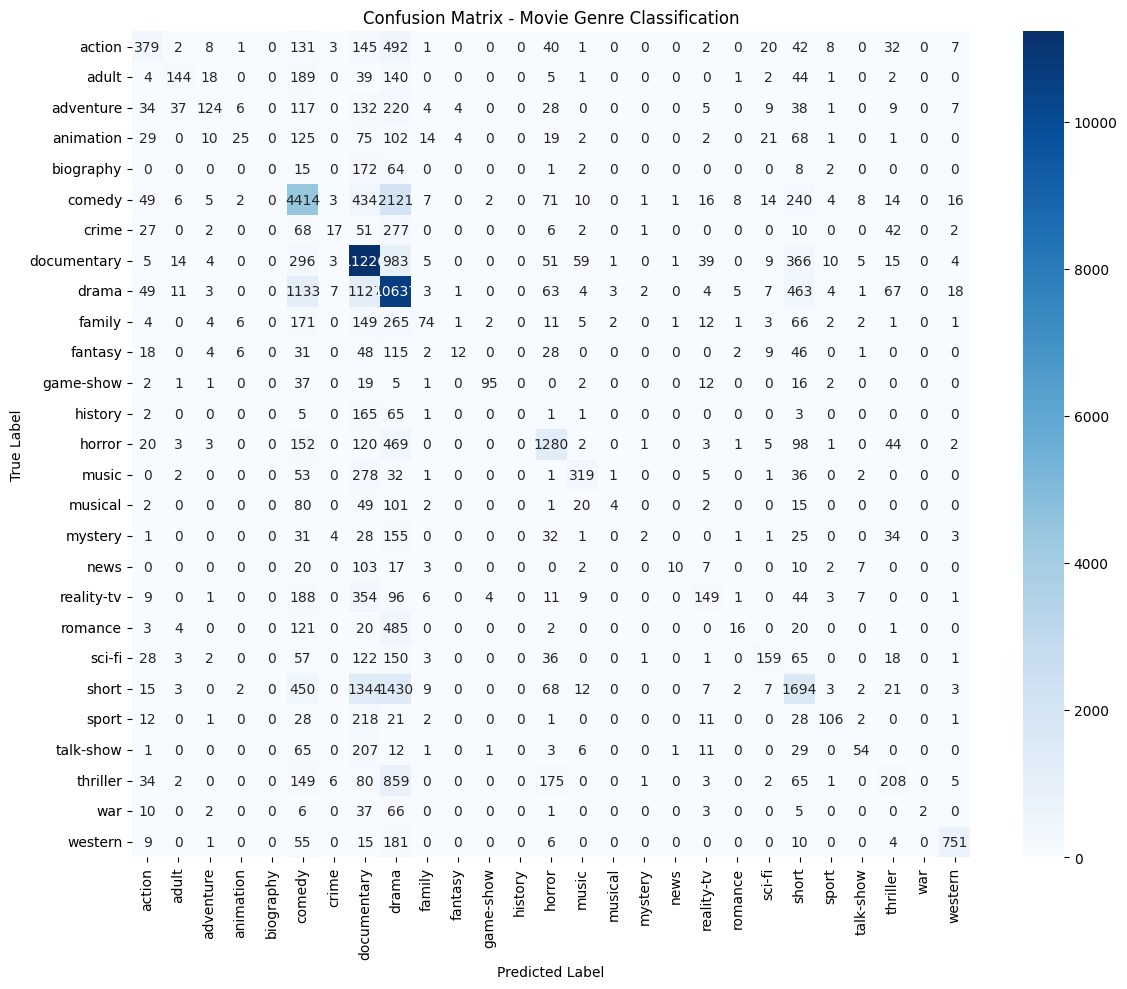

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = sorted(list(set(y_test)))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.title('Confusion Matrix - Movie Genre Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 5: Confusion Matrix Visualization

We generate a normalized graphical heatmap representation of the confusion matrix. This visualization allows us to easily recognize classification trends, observe diagonal alignment indicating accurate predictions, and pinpoint exactly which film genres are most frequently misclassified by our model.